In [3]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import LabelEncoder, StandardScaler 
from sklearn.metrics import confusion_matrix, classification_report,accuracy_score, precision_score, recall_score, f1_score 
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import Dense, Dropout 

In [4]:
# Load the dataset (adjust path if needed) 
df = pd.read_csv("Churn_Modelling.csv") 
# Display basic info 
print(df.head()) 
print(df.info()) 


   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       0  
4         790

In [6]:
# Drop unnecessary columns 
df = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1) 
# Encode categorical variables 
le_gender = LabelEncoder() 
df['Gender'] = le_gender.fit_transform(df['Gender']) 
# One-hot encode Geography (multiple categories) 
df = pd.get_dummies(df, columns=['Geography'], drop_first=True) 
# Separate features and target 
X = df.drop('Exited', axis=1) 
y = df['Exited'] 
# Scale features 
scaler = StandardScaler() 
X_scaled = scaler.fit_transform(X) 
# Split into train-test sets 
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2,random_state=42) 

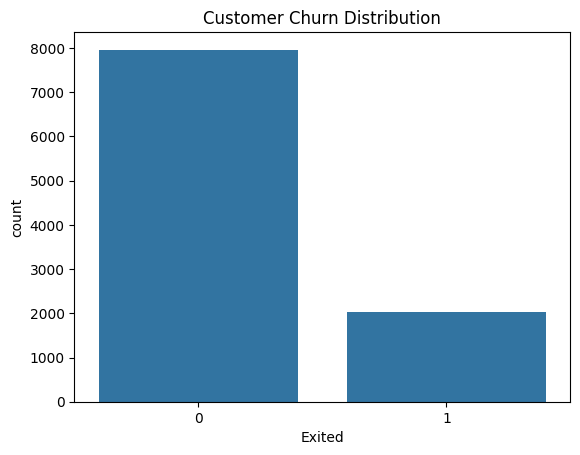

In [7]:
# Check target distribution 
sns.countplot(x='Exited', data=df) 
plt.title("Customer Churn Distribution") 
plt.show() 

In [8]:
model = Sequential([ 
Dense(16, activation='relu', input_dim=X_train.shape[1]), 
Dropout(0.3), 
Dense(8, activation='relu'), 
Dense(1, activation='sigmoid') 
]) 
model.compile(optimizer='adam', loss='binary_crossentropy',metrics=['accuracy']) 
model.summary() 

C:\Users\Sayali\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             192 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(X_train, y_train, epochs=50, batch_size=32,validation_split=0.2, verbose=1) 

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7620 - loss: 0.5356 - val_accuracy: 0.8012 - val_loss: 0.4645
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7945 - loss: 0.4792 - val_accuracy: 0.8087 - val_loss: 0.4389
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7984 - loss: 0.4674 - val_accuracy: 0.8144 - val_loss: 0.4256
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8009 - loss: 0.4471 - val_accuracy: 0.8213 - val_loss: 0.4182
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8070 - loss: 0.4447 - val_accuracy: 0.8288 - val_loss: 0.4122
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8100 - loss: 0.4385 - val_accuracy: 0.8350 - val_loss: 0.4086
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8175 - loss: 0.4309 - val_accuracy: 0.8400 - val_loss: 0.4009
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8180 - loss: 0.4225 - val_accuracy: 0.

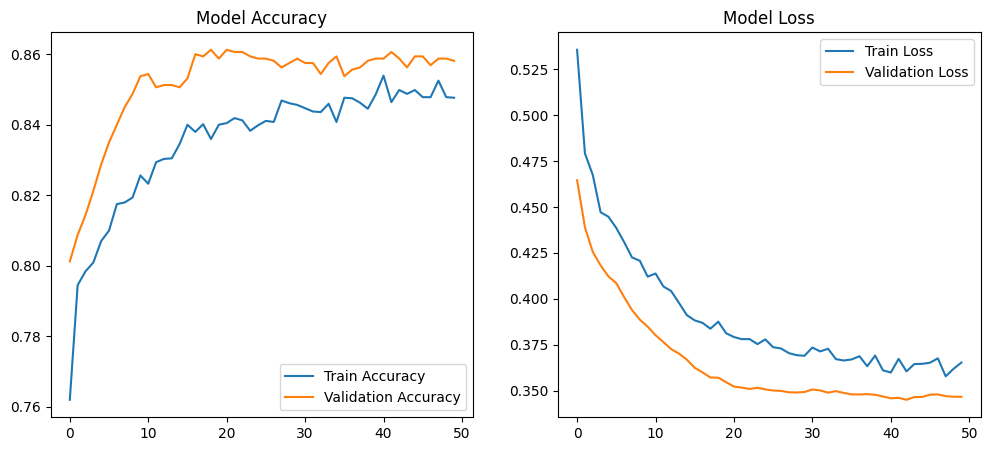

In [10]:
# Plot training & validation accuracy/loss 
plt.figure(figsize=(12,5)) 
plt.subplot(1,2,1) 
plt.plot(history.history['accuracy'], label='Train Accuracy') 
plt.plot(history.history['val_accuracy'], label='Validation Accuracy') 
plt.legend() 
plt.title('Model Accuracy') 
plt.subplot(1,2,2) 
plt.plot(history.history['loss'], label='Train Loss') 
plt.plot(history.history['val_loss'], label='Validation Loss') 
plt.legend() 
plt.title('Model Loss') 
plt.show() 

In [11]:
# Predictions 
y_pred_prob = model.predict(X_test) 
y_pred = (y_pred_prob > 0.5).astype(int) 
# Evaluation Metrics 
acc = accuracy_score(y_test, y_pred) 
prec = precision_score(y_test, y_pred) 
rec = recall_score(y_test, y_pred) 
f1 = f1_score(y_test, y_pred) 
print("Accuracy:", acc) 
print("Precision:", prec) 
print("Recall:", rec) 
print("F1-Score:", f1) 
print("\nClassification Report:\n", classification_report(y_test, y_pred)) 

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Accuracy: 0.8605
Precision: 0.759090909090909
Recall: 0.42493638676844786
F1-Score: 0.5448613376835236

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.97      0.92      1607
           1       0.76      0.42      0.54       393

    accuracy                           0.86      2000
   macro avg       0.82      0.70      0.73      2000
weighted avg       0.85      0.86      0.84      2000



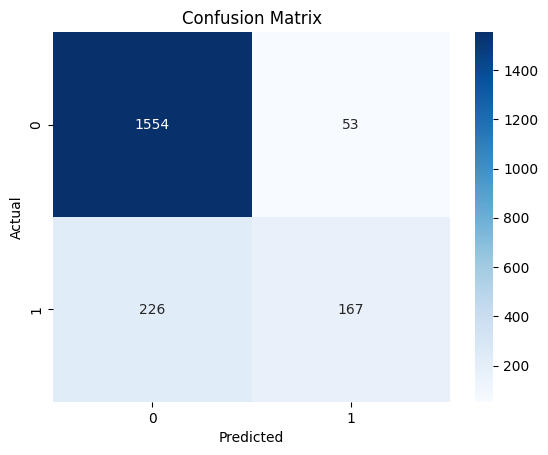

In [12]:
cm = confusion_matrix(y_test, y_pred) 
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues') 
plt.xlabel('Predicted') 
plt.ylabel('Actual') 
plt.title('Confusion Matrix') 
plt.show() 

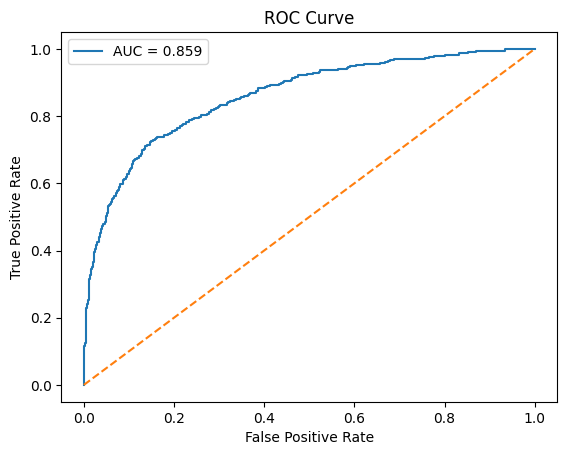

In [13]:
from sklearn.metrics import roc_curve, roc_auc_score 
fpr, tpr, _ = roc_curve(y_test, y_pred_prob) 
roc_auc = roc_auc_score(y_test, y_pred_prob) 
plt.plot(fpr, tpr, label='AUC = %.3f' % roc_auc) 
plt.plot([0,1], [0,1], linestyle='--') 
plt.xlabel('False Positive Rate') 
plt.ylabel('True Positive Rate') 
plt.title('ROC Curve') 
plt.legend() 
plt.show()